# Randomized Grover Iteration Search

## Research question

**Can randomizing the number of Grover iterations reduce sensitivity to an unknown number of marked states $s$?**

The previous investigation showed that one deterministic stopping time can perform extremely well or extremely poorly depending on where it lands on the Grover oscillation.

Instead of committing to one stopping time, choose

$$
j\sim\operatorname{Unif}\{0,1,\ldots,m-1\}.
$$

The algorithm prepares the uniform superposition, applies $j$ Grover iterations, measures, and checks whether the observed state is marked.

This notebook asks

$$
\boxed{
\text{What does averaging over several possible stopping times do to Grover sensitivity?}
}
$$

## 1. Theoretical setup

For

$$
N=2^n
$$

with $s$ marked states,

$$
\sin^2\theta=\frac{s}{N}.
$$

After exactly $j$ Grover iterations,

$$
P(j)=\sin^2((2j+1)\theta).
$$

If $j$ is chosen uniformly from $0$ through $m-1$,

$$
P_m
=
\frac1m
\sum_{j=0}^{m-1}
\sin^2((2j+1)\theta).
$$

Boyer, Brassard, Høyer, and Tapp derive the exact closed form

$$
\boxed{
P_m
=
\frac12
-
\frac{\sin(4m\theta)}
{4m\sin(2\theta)}
}
$$

and show that

$$
\boxed{
P_m\ge\frac14
}
$$

whenever

$$
m\ge\frac1{\sin(2\theta)}.
$$

Define the first integer satisfying this condition as

$$
m_0
=
\left\lceil
\frac1{\sin(2\theta)}
\right\rceil.
$$

For small $s/N$,

$$
m_0
\approx
\frac12\sqrt{\frac Ns}.
$$

### 1.1 Why might randomization help?

A deterministic rule commits the search to one phase location.

Randomization changes the object of interest from one value $P(j)$ to an average over several phase locations.

The question is not whether every sampled $j$ is good.

The question is whether a sufficiently wide range contains enough useful stopping points to prevent catastrophic dependence on one bad choice.

## 2. Implementation

The experiments use ideal statevector simulation. The oracle contains exactly $s$ marked states. Only the number of Grover iterations is randomized.

In [1]:
from math import asin, sqrt, sin, ceil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

try:
    from qiskit.circuit.library import DiagonalGate
except ImportError:
    from qiskit.circuit.library import Diagonal as DiagonalGate

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.3.0


In [2]:
def validate_iteration_count(j):
    """Return j as int after enforcing a nonnegative integer iteration count."""
    if not isinstance(j, (int, np.integer)):
        raise ValueError("j must be a nonnegative integer")
    if j < 0:
        raise ValueError("j must be a nonnegative integer")
    return int(j)


def make_marked_states(n, s):
    N = 2 ** n

    if not 1 <= s < N:
        raise ValueError("s must satisfy 1 <= s < 2**n")

    return [
        format(i, f"0{n}b")
        for i in range(s)
    ]


def build_phase_oracle(n, marked):
    phases = np.ones(
        2 ** n,
        dtype=complex,
    )

    for bitstring in marked:
        phases[int(bitstring, 2)] = -1.0

    return DiagonalGate(
        phases.tolist()
    )


def apply_zero_state_phase_flip(circuit, qubits):
    qubits = list(qubits)

    if len(qubits) == 1:
        q = qubits[0]
        circuit.x(q)
        circuit.z(q)
        circuit.x(q)
        return

    for q in qubits:
        circuit.x(q)

    target = qubits[-1]

    circuit.h(target)
    circuit.mcx(
        qubits[:-1],
        target,
    )
    circuit.h(target)

    for q in qubits:
        circuit.x(q)


def apply_diffusion(circuit, qubits):
    qubits = list(qubits)

    for q in qubits:
        circuit.h(q)

    apply_zero_state_phase_flip(
        circuit,
        qubits,
    )

    for q in qubits:
        circuit.h(q)


def build_grover_circuit(n, marked, j):
    j = validate_iteration_count(j)

    qc = QuantumCircuit(n)
    qc.h(range(n))

    oracle = build_phase_oracle(
        n,
        marked,
    )

    for _ in range(j):
        qc.append(
            oracle,
            range(n),
        )
        apply_diffusion(
            qc,
            range(n),
        )

    return qc


def simulation_success_probability(n, marked, j):
    j = validate_iteration_count(j)

    state = Statevector.from_instruction(
        build_grover_circuit(
            n,
            marked,
            j,
        )
    )

    probs = state.probabilities()

    return float(
        sum(
            probs[int(x, 2)]
            for x in marked
        )
    )

In [3]:
def theta_from_N_s(N, s):
    if N < 2:
        raise ValueError("N must be at least 2")

    if not 1 <= s < N:
        raise ValueError("s must satisfy 1 <= s < N")

    return asin(sqrt(s / N))


def grover_probability(N, s, j):
    j = validate_iteration_count(j)

    theta = theta_from_N_s(N, s)
    return sin((2 * j + 1) * theta) ** 2


def randomized_probability_sum(N, s, m):
    if m < 1:
        raise ValueError("m must be at least 1")

    return float(
        np.mean([
            grover_probability(N, s, j)
            for j in range(m)
        ])
    )


def randomized_probability_closed_form(N, s, m):
    if m < 1:
        raise ValueError("m must be at least 1")

    theta = theta_from_N_s(N, s)
    denominator = 4 * m * sin(2 * theta)

    return float(
        0.5
        - sin(4 * m * theta) / denominator
    )


def bbht_threshold(N, s):
    theta = theta_from_N_s(N, s)
    return int(ceil(1 / sin(2 * theta)))

### 2.1 Domain of the nontrivial search problem

Throughout this notebook,

$$
1\le s<N.
$$

The edge case $s=N$ is trivial because every basis state is marked and the initial uniform state already succeeds with probability $1$.

It is excluded here because the usual marked and unmarked two dimensional Grover decomposition degenerates when no unmarked subspace exists.

## 3. Does the BBHT closed form equal the explicit finite average?

Before interpreting randomized search, verify

$$
\frac1m\sum_{j=0}^{m-1}\sin^2((2j+1)\theta)
$$

against the closed form.

A meaningful discrepancy here would indicate a transcription or implementation error.

In [4]:
identity_cases = [
    (64, 1, 4),
    (64, 4, 5),
    (128, 2, 8),
    (256, 1, 16),
    (256, 8, 7),
    (512, 16, 10),
]

rows = []
for N, s, m in identity_cases:
    p_sum = randomized_probability_sum(N, s, m)
    p_closed = randomized_probability_closed_form(N, s, m)
    rows.append({
        "N": N, "s": s, "m": m,
        "finite_sum": p_sum,
        "closed_form": p_closed,
        "absolute_error": abs(p_sum - p_closed),
    })

identity_df = pd.DataFrame(rows)
identity_df

,N,s,m,finite_sum,closed_form,absolute_error
0,64,1,4,0.271432,0.271432,0.000000e+00
1,64,4,5,0.597325,0.597325,0.000000e+00
2,128,2,8,0.596207,0.596207,0.000000e+00
3,256,1,16,0.594999,0.594999,0.000000e+00
4,256,8,7,0.599089,0.599089,1.110223e-16
5,512,16,10,0.447217,0.447217,0.000000e+00


## 4. Does the statevector implementation reproduce the same randomized average?

For fixed $m$,

$$
P_m^{\mathrm{sim}}
=
\frac1m
\sum_{j=0}^{m-1}
P_{\mathrm{sim}}(j).
$$

We therefore compare

$$
P_m^{\mathrm{closed}},
\qquad
P_m^{\mathrm{sum}},
\qquad
P_m^{\mathrm{sim}}.
$$

In [5]:
simulation_cases = [
    (6, 1, 4),
    (6, 4, 5),
    (7, 2, 8),
    (8, 1, 16),
    (8, 8, 7),
]

rows = []
for n, s, m in simulation_cases:
    N = 2 ** n
    marked = make_marked_states(n, s)
    p_sim = float(np.mean([
        simulation_success_probability(n, marked, j)
        for j in range(m)
    ]))
    p_sum = randomized_probability_sum(N, s, m)
    p_closed = randomized_probability_closed_form(N, s, m)
    rows.append({
        "n": n, "N": N, "s": s, "m": m,
        "closed_form": p_closed,
        "finite_sum": p_sum,
        "statevector_average": p_sim,
        "abs_error_sim_vs_closed": abs(p_sim - p_closed),
    })

simulation_validation_df = pd.DataFrame(rows)
simulation_validation_df

,n,N,s,m,closed_form,finite_sum,statevector_average,abs_error_sim_vs_closed
0,6,64,1,4,0.271432,0.271432,0.271432,6.550316e-15
1,6,64,4,5,0.597325,0.597325,0.597325,1.931788e-14
2,7,128,2,8,0.596207,0.596207,0.596207,3.430589e-14
3,8,256,1,16,0.594999,0.594999,0.594999,2.716716e-13
4,8,256,8,7,0.599089,0.599089,0.599089,4.940492e-14


## 5. What does randomization actually average?

Use the controlled case

$$
N=256,
\qquad
s=4.
$$

At the BBHT threshold, inspect every individual $P(j)$ inside the allowed randomized range.

In [6]:
n_control = 8
N_control = 256
s_control = 4
m_control = bbht_threshold(N_control, s_control)

control_df = pd.DataFrame({
    "j": list(range(m_control)),
    "P_j": [
        grover_probability(N_control, s_control, j)
        for j in range(m_control)
    ],
})

print("BBHT threshold m0:", m_control)
print("Average success:", control_df["P_j"].mean())
control_df

BBHT threshold m0: 5
Average success: 0.3804208053050388


,j,P_j
0,0,0.015625
1,1,0.134827
2,2,0.343895
3,3,0.591380
4,4,0.816377


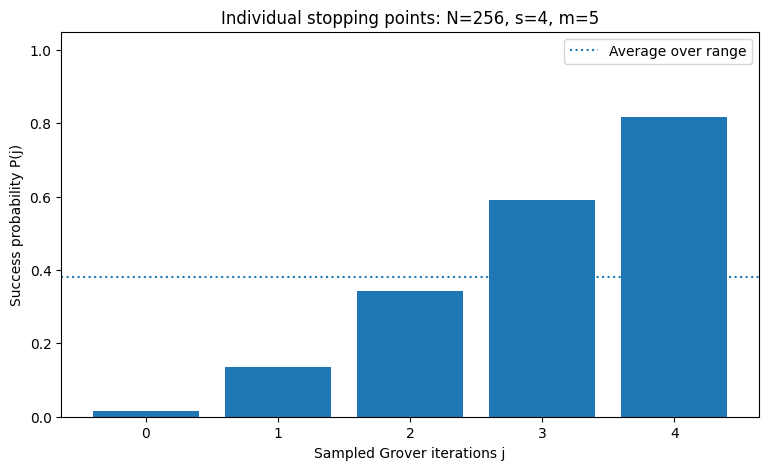

In [7]:
plt.figure(figsize=(9, 5))
plt.bar(control_df["j"], control_df["P_j"])
plt.axhline(
    control_df["P_j"].mean(),
    linestyle=":",
    label="Average over range",
)
plt.xlabel("Sampled Grover iterations j")
plt.ylabel("Success probability P(j)")
plt.title(
    f"Individual stopping points: N={N_control}, "
    f"s={s_control}, m={m_control}"
)
plt.ylim(0, 1.05)
plt.legend()
plt.show()

The range may contain both strong and weak stopping points.

Randomization does not remove Grover oscillation.

It reduces dependence on any single phase location by averaging over several locations.

## 6. How does $P_m$ change as the randomization range grows?

Fix

$$
N=256
$$

and examine several marked counts while varying $m$.

The BBHT theorem predicts that from the threshold

$$
m_0
=
\left\lceil\frac1{\sin(2\theta)}\right\rceil
$$

onward, the exact randomized success probability cannot fall below $1/4$.

In [8]:
N_sweep = 256
s_values = [1, 2, 4, 8, 16]
m_max = 40

rows = []
for s in s_values:
    m0 = bbht_threshold(N_sweep, s)
    for m in range(1, m_max + 1):
        rows.append({
            "N": N_sweep,
            "s": s,
            "m": m,
            "m0": m0,
            "P_m": randomized_probability_closed_form(N_sweep, s, m),
        })

range_df = pd.DataFrame(rows)
range_df.head()

,N,s,m,m0,P_m
0,256,1,1,9,0.003906
1,256,1,2,9,0.019349
2,256,1,3,9,0.044445
3,256,1,4,9,0.078264
4,256,1,5,9,0.119560


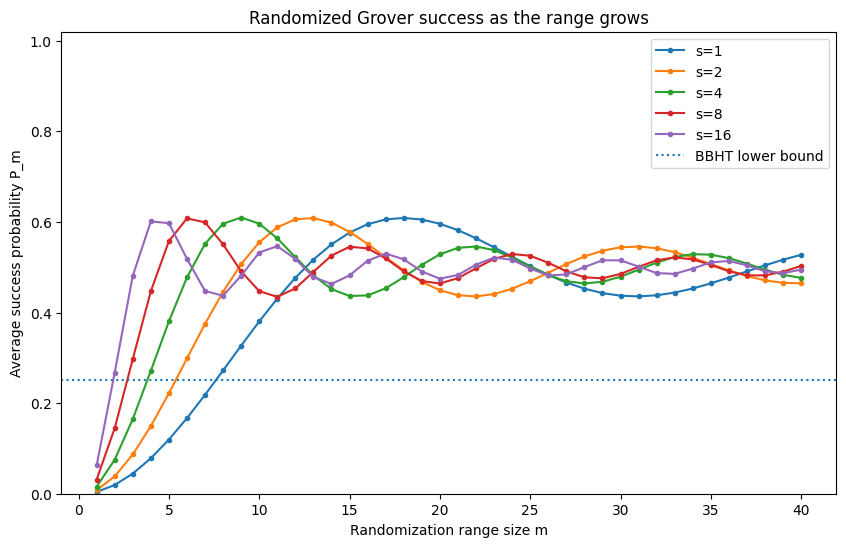

In [9]:
plt.figure(figsize=(10, 6))
for s in s_values:
    subset = range_df[range_df["s"] == s]
    plt.plot(
        subset["m"],
        subset["P_m"],
        marker="o",
        markersize=3,
        label=f"s={s}",
    )

plt.axhline(0.25, linestyle=":", label="BBHT lower bound")
plt.xlabel("Randomization range size m")
plt.ylabel("Average success probability P_m")
plt.title("Randomized Grover success as the range grows")
plt.ylim(0, 1.02)
plt.legend()
plt.show()

## 7. Does the BBHT lower bound appear at the predicted threshold?

In [10]:
rows = []
for s in s_values:
    m0 = bbht_threshold(N_sweep, s)
    tested_ms = list(range(m0, m_max + 1))
    probabilities = [
        randomized_probability_closed_form(N_sweep, s, m)
        for m in tested_ms
    ]
    minimum = min(probabilities)
    rows.append({
        "N": N_sweep,
        "s": s,
        "m0": m0,
        "minimum_P_for_m_ge_m0": minimum,
        "m_at_minimum": tested_ms[int(np.argmin(probabilities))],
        "bound_satisfied": minimum >= 0.25 - 1e-12,
    })

bbht_bound_df = pd.DataFrame(rows)
bbht_bound_df

,N,s,m0,minimum_P_for_m_ge_m0,m_at_minimum,bound_satisfied
0,256,1,9,0.326962,9,True
1,256,2,6,0.298677,6,True
2,256,4,5,0.380421,5,True
3,256,8,3,0.297325,3,True
4,256,16,3,0.437176,8,True


The significance of the $1/4$ result is not that one randomized trial is almost certain to succeed.

It is that once the range reaches the correct scale, success cannot collapse arbitrarily close to zero.

A constant success probability is enough to support a repeated search strategy.

## 8. Monte Carlo experiment

The exact $P_m$ is an expectation over both the random choice of $j$ and the quantum measurement.

A single finite Monte Carlo run can deviate noticeably from that expectation by chance. To distinguish ordinary sampling fluctuation from a systematic problem, the experiment is repeated across several independent random seeds.

For each replicate:

1. sample $j$ uniformly from $0$ through $m-1$,
2. use the ideal statevector probability associated with that $j$,
3. sample a Bernoulli measurement outcome,
4. repeat for many trials.

The experiment below uses

$$
10
$$

independent replicates with

$$
20{,}000
$$

trials per replicate, giving

$$
200{,}000
$$

trials for each value of $s$.

The pooled empirical success probability is compared with the exact $P_m$. A Wilson confidence interval is reported because it is more stable for a binomial proportion than the simplest normal approximation.

In [11]:
def wilson_interval(successes, trials, z=1.96):
    p_hat = successes / trials

    denominator = 1 + z**2 / trials

    center = (
        p_hat + z**2 / (2 * trials)
    ) / denominator

    half_width = (
        z
        * sqrt(
            p_hat * (1 - p_hat) / trials
            + z**2 / (4 * trials**2)
        )
        / denominator
    )

    return (
        max(0.0, center - half_width),
        min(1.0, center + half_width),
    )


def monte_carlo_replicates(
    n,
    s,
    m,
    trials_per_replicate=20_000,
    replicates=10,
    base_seed=1000,
):
    N = 2 ** n
    marked = make_marked_states(n, s)

    probability_cache = {
        j: simulation_success_probability(
            n,
            marked,
            j,
        )
        for j in range(m)
    }

    replicate_estimates = []
    total_successes = 0
    total_trials = 0

    for r in range(replicates):
        seed = base_seed + s + 10_000 * r
        rng = np.random.default_rng(seed)

        sampled_j = rng.integers(
            low=0,
            high=m,
            size=trials_per_replicate,
        )

        successes = np.array([
            rng.random() < probability_cache[int(j)]
            for j in sampled_j
        ], dtype=int)

        replicate_estimates.append(
            float(successes.mean())
        )

        total_successes += int(successes.sum())
        total_trials += trials_per_replicate

    pooled_success = total_successes / total_trials
    ci_low, ci_high = wilson_interval(
        total_successes,
        total_trials,
    )

    theory = randomized_probability_closed_form(
        N,
        s,
        m,
    )

    return {
        "n": n,
        "N": N,
        "s": s,
        "m": m,
        "replicates": replicates,
        "trials_per_replicate": trials_per_replicate,
        "total_trials": total_trials,
        "empirical_success": pooled_success,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "theory_P_m": theory,
        "theory_inside_CI": ci_low <= theory <= ci_high,
        "replicate_mean": float(np.mean(replicate_estimates)),
        "replicate_sd": float(np.std(
            replicate_estimates,
            ddof=1,
        )),
        "replicate_min": float(np.min(replicate_estimates)),
        "replicate_max": float(np.max(replicate_estimates)),
    }


mc_rows = []

for s in [1, 2, 4, 8, 16]:
    n = 8
    N = 2 ** n
    m = bbht_threshold(N, s)

    mc_rows.append(
        monte_carlo_replicates(
            n=n,
            s=s,
            m=m,
            trials_per_replicate=20_000,
            replicates=10,
            base_seed=1000,
        )
    )

monte_carlo_df = pd.DataFrame(mc_rows)
monte_carlo_df

,n,N,s,m,replicates,trials_per_replicate,total_trials,empirical_success,ci_low,ci_high,theory_P_m,theory_inside_CI,replicate_mean,replicate_sd,replicate_min,replicate_max
0,8,256,1,9,10,20000,200000,0.326675,0.324623,0.328734,0.326962,True,0.326675,0.004183,0.32020,0.33385
1,8,256,2,6,10,20000,200000,0.298015,0.296014,0.300023,0.298677,True,0.298015,0.002662,0.29500,0.30305
2,8,256,4,5,10,20000,200000,0.381270,0.379144,0.383401,0.380421,True,0.381270,0.000900,0.37995,0.38270
3,8,256,8,3,10,20000,200000,0.296500,0.294502,0.298506,0.297325,True,0.296500,0.003222,0.29130,0.30190
4,8,256,16,3,10,20000,200000,0.479655,0.477466,0.481845,0.481201,True,0.479655,0.001771,0.47740,0.48405


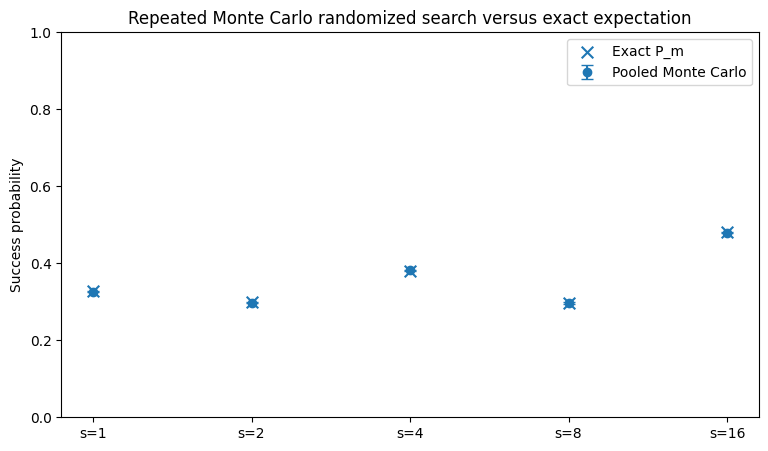

In [12]:
plt.figure(figsize=(9, 5))

x = np.arange(len(monte_carlo_df))

empirical = monte_carlo_df[
    "empirical_success"
].to_numpy()

theory = monte_carlo_df[
    "theory_P_m"
].to_numpy()

lower_error = (
    empirical
    - monte_carlo_df["ci_low"].to_numpy()
)

upper_error = (
    monte_carlo_df["ci_high"].to_numpy()
    - empirical
)

plt.errorbar(
    x,
    empirical,
    yerr=np.vstack([
        lower_error,
        upper_error,
    ]),
    fmt="o",
    capsize=4,
    label="Pooled Monte Carlo",
)

plt.scatter(
    x,
    theory,
    marker="x",
    s=70,
    label="Exact P_m",
)

plt.xticks(
    x,
    [
        f"s={s}"
        for s in monte_carlo_df["s"]
    ],
)

plt.ylabel("Success probability")
plt.title(
    "Repeated Monte Carlo randomized search versus exact expectation"
)
plt.ylim(0, 1)
plt.legend()
plt.show()

## 9. Probability versus Grover iteration cost

For

$$
j\sim\operatorname{Unif}\{0,\ldots,m-1\},
$$

the expected number of Grover iterations in one randomized trial is

$$
\mathbb{E}[j]
=
\frac{m-1}{2}.
$$

At the BBHT threshold and for small $s/N$,

$$
\mathbb{E}[j]
\approx
\frac14\sqrt{\frac Ns}.
$$

A larger $m$ can stabilize the average probability, but it also increases the expected number of Grover iterations.

In this notebook, cost is reported first in Grover iterations. Under the phase oracle model used here, one Grover iteration contains one application of the search oracle. Candidate verification after measurement is a separate oracle use and is not included in this section.

So success probability alone is not enough.

In [13]:
cost_rows = []
for s in s_values:
    m0 = bbht_threshold(N_sweep, s)
    cost_rows.append({
        "N": N_sweep,
        "s": s,
        "m0": m0,
        "expected_j_at_m0": (m0 - 1) / 2,
        "sqrt_N_over_s": sqrt(N_sweep / s),
        "ratio_expected_j_to_sqrt_scale": (
            ((m0 - 1) / 2) / sqrt(N_sweep / s)
        ),
        "P_m0": randomized_probability_closed_form(N_sweep, s, m0),
    })

cost_df = pd.DataFrame(cost_rows)
cost_df

,N,s,m0,expected_j_at_m0,sqrt_N_over_s,ratio_expected_j_to_sqrt_scale,P_m0
0,256,1,9,4.0,16.000000,0.250000,0.326962
1,256,2,6,2.5,11.313708,0.220971,0.298677
2,256,4,5,2.0,8.000000,0.250000,0.380421
3,256,8,3,1.0,5.656854,0.176777,0.297325
4,256,16,3,1.0,4.000000,0.250000,0.481201


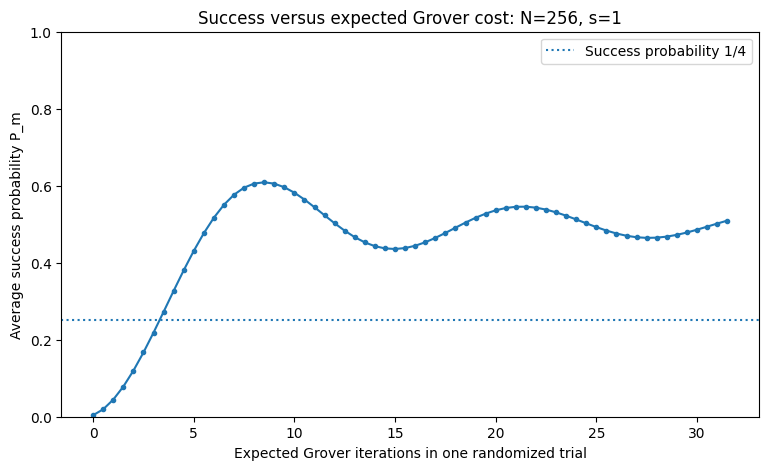

In [14]:
s_tradeoff = 1
N_tradeoff = 256

tradeoff_df = pd.DataFrame({
    "m": list(range(1, 65)),
})

tradeoff_df["P_m"] = [
    randomized_probability_closed_form(N_tradeoff, s_tradeoff, m)
    for m in tradeoff_df["m"]
]

tradeoff_df["expected_j"] = (tradeoff_df["m"] - 1) / 2

plt.figure(figsize=(9, 5))
plt.plot(
    tradeoff_df["expected_j"],
    tradeoff_df["P_m"],
    marker="o",
    markersize=3,
)
plt.axhline(0.25, linestyle=":", label="Success probability 1/4")
plt.xlabel("Expected Grover iterations in one randomized trial")
plt.ylabel("Average success probability P_m")
plt.title(f"Success versus expected Grover cost: N={N_tradeoff}, s={s_tradeoff}")
plt.ylim(0, 1)
plt.legend()
plt.show()

## 10. Randomized range versus one deterministic stopping time

A perfectly chosen deterministic stopping time can outperform randomization.

That is not the comparison of interest.

The important question is whether randomization protects against catastrophic dependence on one poor stopping point.

In [15]:
comparison_rows = []

for s in [1, 2, 4, 8, 16]:
    N = 256
    m0 = bbht_threshold(N, s)

    candidate_j = sorted(set([
        0,
        max(0, m0 // 4),
        max(0, m0 // 2),
        max(0, m0 - 1),
        m0,
        2 * m0,
    ]))

    p_random = randomized_probability_closed_form(N, s, m0)

    for j in candidate_j:
        comparison_rows.append({
            "s": s,
            "j": j,
            "P_deterministic": grover_probability(N, s, j),
            "m_random": m0,
            "P_randomized": p_random,
        })

deterministic_vs_random_df = pd.DataFrame(comparison_rows)
deterministic_vs_random_df

,s,j,P_deterministic,m_random,P_randomized
0,1,0,0.003906,9,0.326962
1,1,2,0.094638,9,0.326962
2,1,4,0.284743,9,0.326962
3,1,8,0.763722,9,0.326962
4,1,9,0.860676,9,0.326962
5,1,18,0.542136,9,0.326962
6,2,0,0.007813,6,0.298677
7,2,1,0.068855,6,0.298677
8,2,3,0.337154,6,0.298677
9,2,5,0.683735,6,0.298677


## 11. Analysis questions

### 11.1 Does the closed form agree with the finite average?

Yes.

The explicit finite average and the BBHT closed form agree to floating point precision across all tested cases.

The largest observed discrepancy was approximately

$$
1.11\times10^{-16}.
$$

So the numerical implementation of

$$
P_m
=
\frac1m
\sum_{j=0}^{m-1}
\sin^2((2j+1)\theta)
$$

is consistent with

$$
P_m
=
\frac12
-
\frac{\sin(4m\theta)}
{4m\sin(2\theta)}.
$$

### 11.2 Does the statevector average reproduce the same quantity?

Yes.

The statevector average agrees with both the explicit finite sum and the BBHT closed form to numerical precision.

Across the tested configurations, the remaining differences are only at the scale of floating point arithmetic.

Thus,

$$
\boxed{
P_m^{\mathrm{closed}}
\approx
P_m^{\mathrm{sum}}
\approx
P_m^{\mathrm{sim}}
}
$$

for the tested values of $N$, $s$, and $m$.

### 11.3 What does randomization smooth?

Randomization smooths the algorithm's dependence on one particular stopping time.

It does not remove the underlying Grover oscillation.

For

$$
N=256,
\qquad
s=4,
\qquad
m_0=5,
$$

the individual success probabilities inside the randomized range vary from approximately

$$
0.015625
$$

to

$$
0.816377,
$$

while their average is

$$
P_{m_0}
\approx
0.380421.
$$

So a stable randomized average can coexist with highly variable individual stopping points.

### 11.4 Does the $1/4$ lower bound appear from the predicted threshold onward?

Yes, throughout the tested region.

For

$$
N=256
$$

and

$$
s\in\{1,2,4,8,16\},
$$

every tested value beginning at

$$
m_0
=
\left\lceil
\frac1{\sin(2\theta)}
\right\rceil
$$

remained above

$$
\frac14.
$$

The minimum observed values were approximately

$$
0.326962,\;
0.298677,\;
0.380421,\;
0.297325,\;
0.437176.
$$

This empirically reproduces the BBHT lower bound over the tested range. The theorem itself provides the general guarantee.

### 11.5 Does randomization remove dependence on $s$?

No.

The useful scale of $m$ still depends on

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}}.
$$

Equivalently,

$$
\frac1{\sin(2\theta)}
=
\frac{N}{2\sqrt{s(N-s)}}.
$$

For

$$
s\ll N,
$$

this gives

$$
m_0
\approx
\frac12
\sqrt{\frac{N}{s}}.
$$

Randomization removes the need to choose one exact stopping time, but it does not yet tell us how large the randomization range should be when $s$ is unknown.

### 11.6 What happens when $m$ becomes large?

For fixed

$$
0<s<N,
$$

the correction term in

$$
P_m
=
\frac12
-
\frac{\sin(4m\theta)}
{4m\sin(2\theta)}
$$

vanishes as $m$ grows.

Therefore,

$$
\boxed{
P_m\rightarrow\frac12
}
$$

as

$$
m\rightarrow\infty.
$$

At the same time,

$$
\mathbb{E}[j]
=
\frac{m-1}{2},
$$

so the expected number of Grover iterations grows linearly with $m$.

Thus, making $m$ arbitrarily large stabilizes the success probability near one half but becomes increasingly inefficient.

### 11.7 What question remains?

The remaining problem is

$$
\boxed{
\text{How can the algorithm reach a useful }m\text{ without knowing }s?
}
$$

Fixed range randomization changes the original problem from choosing one exact stopping time to choosing an appropriate randomization range.

That motivates an adaptive geometrically increasing range, leading directly to the BBHT unknown $s$ search procedure.

## 12. Results and interpretation

### 12.1 The BBHT closed form is reproduced numerically

The explicit finite average

$$
\frac1m
\sum_{j=0}^{m-1}
\sin^2((2j+1)\theta)
$$

agrees with the BBHT closed form

$$
P_m
=
\frac12
-
\frac{\sin(4m\theta)}
{4m\sin(2\theta)}
$$

to floating point precision in every tested case.

The largest observed discrepancy in the identity check was approximately

$$
1.11\times10^{-16}.
$$

This confirms that the implemented analytical expression and the direct finite average represent the same quantity.

### 12.2 The statevector implementation reproduces the randomized expectation

The statevector average also agrees with both theoretical calculations to numerical precision.

Across the tested configurations, the remaining differences are at approximately the scale expected from floating point arithmetic.

Thus,

$$
\boxed{
P_m^{\mathrm{closed}}
\approx
P_m^{\mathrm{sum}}
\approx
P_m^{\mathrm{sim}}
}
$$

for the tested values of $N$, $s$, and $m$.

### 12.3 Randomization averages both weak and strong stopping points

For the controlled case

$$
N=256,
\qquad
s=4,
$$

the BBHT threshold is

$$
m_0=5.
$$

The randomized range therefore contains

$$
j\in\{0,1,2,3,4\}.
$$

The corresponding individual success probabilities are approximately

$$
0.015625,
\quad
0.134827,
\quad
0.343895,
\quad
0.591380,
\quad
0.816377.
$$

Their average is

$$
P_{m_0}
\approx
0.380421.
$$

This illustrates the mechanism directly.

Randomization does not make every stopping point good. Instead, it prevents the procedure from depending entirely on one particular phase location.

### 12.4 The BBHT lower bound is reproduced

For

$$
N=256
$$

and

$$
s\in\{1,2,4,8,16\},
$$

the minimum observed value of $P_m$ over the tested region beginning at $m_0$ was:

| $s$ | $m_0$ | minimum $P_m$ for tested $m\ge m_0$ |
| ---: | ---: | ---: |
| 1 | 9 | 0.326962 |
| 2 | 6 | 0.298677 |
| 4 | 5 | 0.380421 |
| 8 | 3 | 0.297325 |
| 16 | 3 | 0.437176 |

Every tested value remains above

$$
\frac14.
$$

This is consistent with the BBHT result that

$$
P_m\ge\frac14
$$

once

$$
m\ge\frac1{\sin(2\theta)}.
$$

The significance is not that one randomized trial becomes nearly certain to succeed. The significance is that the average success probability no longer collapses arbitrarily close to zero once the randomization range reaches the appropriate scale.

### 12.5 Repeated Monte Carlo sampling agrees with the exact expectation

The final Monte Carlo experiment uses

$$
10
$$

independent replicates of

$$
20{,}000
$$

trials each, giving

$$
200{,}000
$$

trials per tested value of $s$.

Using the fixed seeds defined in the experiment, the pooled results are approximately:

| $s$ | empirical success | exact $P_m$ |
| ---: | ---: | ---: |
| 1 | 0.326675 | 0.326962 |
| 2 | 0.298015 | 0.298677 |
| 4 | 0.381270 | 0.380421 |
| 8 | 0.296500 | 0.297325 |
| 16 | 0.479655 | 0.481201 |

For every tested case, the exact randomized expectation lies inside the corresponding Wilson confidence interval.

The empirical estimates therefore agree with the exact randomized probabilities to the precision expected from finite Monte Carlo sampling.

### 12.6 The useful range appears on the square root scale

The BBHT threshold is

$$
m_0
=
\left\lceil
\frac{1}{\sin(2\theta)}
\right\rceil.
$$

Since

$$
\sin^2\theta
=
\frac{s}{N},
$$

we have

$$
\sin(2\theta)
=
2\sin\theta\cos\theta
=
2
\sqrt{\frac{s}{N}}
\sqrt{1-\frac{s}{N}}.
$$

Therefore, before taking the final integer ceiling,

$$
\frac{1}{\sin(2\theta)}
=
\frac{N}
{2\sqrt{s(N-s)}}.
$$

In the sparse solution regime

$$
s\ll N,
$$

this becomes

$$
m_0
\approx
\frac12
\sqrt{\frac{N}{s}}.
$$

For a uniform random choice

$$
j\sim
\operatorname{Unif}
\{0,\ldots,m_0-1\},
$$

the expected number of Grover iterations is

$$
\mathbb{E}[j]
=
\frac{m_0-1}{2}
\approx
\frac14
\sqrt{\frac{N}{s}}.
$$

The executed data are consistent with this scale.

For example, at

$$
N=256,
\qquad
s=1,
$$

the threshold is

$$
m_0=9,
$$

so

$$
\mathbb{E}[j]=4,
$$

while

$$
\sqrt{\frac{N}{s}}=16.
$$

Thus

$$
\frac{\mathbb{E}[j]}
{\sqrt{N/s}}
=
0.25.
$$

The important point is that the square root behavior is not only suggested by the numerical table. It follows analytically from the BBHT threshold in the sparse solution regime.

### 12.7 Randomization reduces catastrophic single point dependence

The deterministic comparison shows why this matters.

For example, with

$$
N=256,
\qquad
s=16,
$$

a deterministic choice of

$$
j=6
$$

has success probability only around

$$
0.0204.
$$

By contrast, randomizing with the threshold range

$$
m_0=3
$$

gives

$$
P_{m_0}
\approx
0.4812.
$$

So randomization can protect the search from a particularly poor deterministic stopping point.

However, it does not dominate a well chosen deterministic stopping time.

For the same problem, a deterministic choice near the first useful maximum can achieve success probability close to one.

The correct interpretation is therefore

$$
\boxed{
\text{randomization sacrifices peak performance to reduce dependence on one precise stopping point.}
}
$$

### 12.8 Large range behavior

Analysis Question 11.6 asks what happens when the randomization range becomes large.

For fixed

$$
0<s<N,
$$

the randomized success probability is

$$
P_m
=
\frac12
-
\frac{\sin(4m\theta)}
{4m\sin(2\theta)}.
$$

Because

$$
|\sin(4m\theta)|
\le
1,
$$

the correction term satisfies

$$
\left|
\frac{\sin(4m\theta)}
{4m\sin(2\theta)}
\right|
\le
\frac{1}
{4m|\sin(2\theta)|}.
$$

Therefore,

$$
\boxed{
\lim_{m\to\infty}P_m
=
\frac12.
}
$$

At the same time,

$$
\mathbb{E}[j]
=
\frac{m-1}{2},
$$

so

$$
\boxed{
\mathbb{E}[j]
\to
\infty
\quad
\text{linearly in }m.
}
$$

This produces an important tradeoff.

Increasing $m$ eventually stabilizes the average success probability near one half, but it also keeps increasing the expected Grover cost of one randomized trial.

Thus, choosing an arbitrarily large range is not an efficient solution to unknown $s$.

The useful goal is not

$$
m\rightarrow\infty,
$$

but rather to reach a range of the correct order without knowing that order in advance.

This is exactly why an adaptive increasing range becomes necessary.

### 12.9 What randomization does not solve

The strategy has removed the need to identify one exact Grover iteration count, but it has introduced a different parameter:

$$
m.
$$

The useful threshold depends on

$$
\theta
=
\arcsin\sqrt{\frac{s}{N}},
$$

and therefore still depends on the unknown marked count.

So fixed range randomization does not yet solve unknown $s$.

It changes the problem from

$$
\text{Which exact }j\text{ should be used?}
$$

to

$$
\text{How large should the randomization range }m\text{ be?}
$$

That is precisely the question addressed by an adaptive increasing range.

## 13. Conclusion and next research question

The experiments show that randomizing the Grover iteration count provides a meaningful form of robustness against an unknown stopping point.

The BBHT closed form, the explicit finite average, and the ideal statevector implementation agree to numerical precision.

Once the range reaches the BBHT threshold scale, the tested average success probabilities remain above the theoretical lower bound of

$$
\frac14.
$$

Repeated Monte Carlo experiments also converge closely to the exact expectation.

The main tradeoff is now clear.

A deterministic stopping time can achieve much higher success when it is chosen correctly, but it can also fail catastrophically when it lands at a poor phase location.

A randomized range gives up some of that peak performance in exchange for reduced dependence on one precise iteration count.

Making the range arbitrarily large is not sufficient either. The average success probability approaches $1/2$, while the expected number of Grover iterations grows linearly with $m$.

The useful range size $m$ therefore still has to be reached efficiently, even though its natural scale depends on the unknown quantity $s$.

The next research question is therefore

$$
\boxed{
\text{Can }m\text{ be increased adaptively so that the useful scale is reached without prior knowledge of }s\text{?}
}
$$

That leads directly to the adaptive search procedure of Boyer, Brassard, Høyer, and Tapp.

## References

1. Michel Boyer, Gilles Brassard, Peter Høyer, and Alain Tapp, *Tight bounds on quantum searching*.
2. Lov K. Grover, *A fast quantum mechanical algorithm for database search*.
3. Gilles Brassard, Peter Høyer, Michele Mosca, and Alain Tapp, *Quantum Amplitude Amplification and Estimation*.